<img src="https://www.javeriana.edu.co/recursosdb/20125/5571273/escudo-circular.png" alt="Your Image" style="float:left;">
</div><h1>Pontificia Universidad Javeriana</h1>

<h1> Taller de Procesamiento de Lenguaje Natural</h1>

### Integrantes:


In [ ]:
!python -m spacy download es_core_news_md -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 29.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import math
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.util import ngrams
from nltk import word_tokenize
nltk.download('stopwords')

import spacy
nlp = spacy.load("es_core_news_md")

from wordcloud import WordCloud


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


2.1 Carga de los datos

In [ ]:
# Lectura de base de datos de sentencias

df = pd.read_csv("hf://datasets/Manuel/sentencias-corte-cons-colombia-1992-2021/Juris1992_2022.csv")



2.2 Exploración de los datos

In [ ]:
#tipo de dato en el que estan contenidas la sentencias
type(df)

pandas.core.frame.DataFrame

In [ ]:
# cuantas sentencias tenemos
len(df)

23750

In [ ]:
df = df.sample(n=1000, random_state=42)
df["numero_palabras"] = (
    df["Texto"]
    .fillna("")
    .str.split()
    .str.len()
)


In [ ]:
df["numero_palabras"].sum()/1000

271907978/23750

11448.756968421052

Para hacer la exploración de las sentencias de forma ordenada, lo primero es establecer el consecutivo o nombre de la sentencia. Con esto se puede nombrar y determinar la fecha en la que fue proferida.

Se identifica que en este caso los primero 8 caracteres de cada sentencia hace referencia al numero consecutivo que la identifica.

In [ ]:
def limpiar_texto(texto):
    # Minúsculas
    texto = texto.lower()

    # Proteger la ñ temporalmente
    texto = texto.replace("ñ", "__enie__")

    # Quitar tildes y otros diacríticos
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    )

    # Restaurar la ñ
    texto = texto.replace("__enie__", "ñ")

    # Dejar letras a-z, ñ, números y espacios (se dejan los numero temporalmente porque seran los que determinen el ID y fecha de la sentencia)
    texto = re.sub(r"[^a-zñ0-9\s]", " ", texto)

    # Normalizar espacios, tabs y saltos de línea
    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()

In [ ]:
df["SENTENCIA_LIMPIA"] = df["Texto"].apply(limpiar_texto)

Se identifica que el nombre y año de la sentencia se encuetra expresado por un conscutivo en los primero 8 caracteres de cada texto. El año en especifico son los ultimos dos de esta cadena de 8.

In [ ]:
import re

df["SENTENCIA_LIMPIA"] = df["SENTENCIA_LIMPIA"].str.replace(
    r"^\s*sentencia\b\s*",
    "",
    regex=True,
    case=False
)

In [ ]:
df['SENTENCIA'] = df['SENTENCIA_LIMPIA'].str.strip().str[:8]
df['ANNIO'] = df['SENTENCIA_LIMPIA'].str.strip().str[6:8]

Teniendo en cuenta que parte del proposito es hacer una evaluación temporal del lenguaje en las sentencias, aquellas que no se puede establecer temporalidad podrian ser descartadas del corpus.

In [ ]:
df = df[df["ANNIO"].str.match(r"^\d{2}$", na=False)]

In [ ]:
df['ANNIO'].unique()


array(['21', '92', '95', '93', '94', '97', '96', '00', '98', '99', '01',
       '02', '03', '05', '04', '08', '07', '06', '09', '10', '20', '18',
       '19', '12', '15', '13', '14', '16', '17', '11'], dtype=object)

Agregar por delante información para completar el año y poder establecer un orden cronologico que entienda pandas.

In [ ]:
df['ANNIO'] = df['ANNIO'].astype(str).apply(
    lambda x: '19' + x if 90 <= int(x) <= 99 else '20' + x
)

In [ ]:
df = df.sort_values(by='ANNIO')

Ya que se hizo la identiicacion del ID de la sentencia y su año de emision se puede realizar de nuevo la limpieza de los numeros para dejar unicamente cadenas de texto.

In [ ]:
def limpiar_texto(texto):
    # Minúsculas
    texto = texto.lower()

    # Proteger la ñ temporalmente
    texto = texto.replace("ñ", "__enie__")

    # Quitar tildes y otros diacríticos
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    )

    # Restaurar la ñ
    texto = texto.replace("__enie__", "ñ")

    # Dejar letras a-z, ñ, números y espacios
    texto = re.sub(r"[^a-zñ\s]", " ", texto)

    # Normalizar espacios, tabs y saltos de línea
    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()

In [ ]:
df["SENTENCIA_LIMPIA"] = df["Texto"].apply(limpiar_texto)

Tokenizar y eliminar stopwords con NLTK en español

In [ ]:
stopwords_es = set(stopwords.words("spanish"))

def tokenizar_sin_stopwords(texto):
    # Tokeniza y elimina stopwords
    words = [word for word in word_tokenize(texto, "spanish") if word not in stopwords_es and word.isalnum()]
    return words

def palabras_vacias(texto):
    # Almacena las stopwords
    words = [word for word in word_tokenize(texto, "spanish") if word in stopwords_es and word.isalnum()]
    return words


In [ ]:
nltk.download('punkt_tab')
df["tokens_nltk"] = df["SENTENCIA_LIMPIA"].apply(tokenizar_sin_stopwords)
df["stopwords_nltk"] = df["SENTENCIA_LIMPIA"].apply(palabras_vacias)


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Tabla descriptiva con la informacion relevante de cada una de las sentencias.

In [ ]:
def longitud(iterable):
    return len(iterable)

df_conteos = pd.DataFrame({
    "SENTENCIA": df["SENTENCIA"],
    "TOT_PALABRAS": df["SENTENCIA_LIMPIA"].apply(lambda x: len(x.split())),
    "tokens": df["tokens_nltk"].apply(longitud),
    "stopwords": df["stopwords_nltk"].apply(longitud),
})

df_conteos

,SENTENCIA,TOT_PALABRAS,tokens,stopwords
5974,c 255 99,7765,4071,3694
21726,t 592 16,10206,5293,4913
8562,t 577 03,3865,1977,1888
15060,t 039 10,9189,4811,4378
14580,t 658 09,7492,4122,3370
...,...,...,...,...
22961,t 204 11,6208,3297,2911
11314,t 236 08,6574,3386,3188
12121,t 030 07,7338,3797,3541
2141,t 193 97,4336,2240,2096


In [ ]:
df.columns

Index(['Unnamed: 0', 'Texto', 'SENTENCIA_LIMPIA', 'SENTENCIA', 'ANNIO',
       'tokens_nltk', 'stopwords_nltk'],
      dtype='object')

Funcion para crear graficas de frecuencia de palabras

In [ ]:
def frecuencia_terminos(
    df: pd.DataFrame,
    col_sentencia: str = "SENTENCIA",
    col_lemas: str = "tokens_nltk",
    top_n: int = 20,
    n_cols: int = 2,
    paleta: str = "viridis"
):
    """
    Grafica los términos más frecuentes en cada sentencia utilizando Seaborn.
    """
    # Definir el tema global de Seaborn para limpieza visual
    # 'whitegrid' facilita la lectura de gráficos de barras sin saturar de tinta
    sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

    datos = df.copy()

    sentencias = datos[col_sentencia].unique()
    n_sentencias = len(sentencias)
    n_rows = math.ceil(n_sentencias / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(7 * n_cols, 5 * n_rows),
        constrained_layout=True
    )

    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    frecuencias = {}

    for ax, sentencia in zip(axes, sentencias):

        subconjunto = datos[datos[col_sentencia] == sentencia]

        terminos = [lema for lista_lemas in subconjunto[col_lemas]
                    if isinstance(lista_lemas, (list, tuple)) for lema in lista_lemas]

        contador = Counter(terminos)
        top_terminos = contador.most_common(top_n)

        df_freq = pd.DataFrame(top_terminos, columns=["termino", "frecuencia"])
        frecuencias[sentencia] = df_freq

        # Orden descendente
        df_plot = df_freq.sort_values("frecuencia", ascending=False)

        # Implementación
        sns.barplot(
            data=df_plot,
            x="frecuencia",
            y="termino",
            ax=ax,
            palette=paleta,
            hue="termino",
            legend=False
        )

        ax.set_title(f"{sentencia}", fontsize=13, fontweight="bold", pad=10)
        ax.set_xlabel("Frecuencia")
        ax.set_ylabel("") # Se elimina la etiqueta 'Término' por ser semánticamente obvia

    # Ocultar subplots vacíos
    for ax in axes[n_sentencias:]:
        ax.set_visible(False)

    fig.suptitle(
        f"Top {top_n} términos más frecuentes en cada sentencia",
        fontsize=16,
        fontweight="bold"
    )

    plt.show()
    return frecuencias

Grafica de las 20 palabras mas utilizadas en cada una de las sentencias

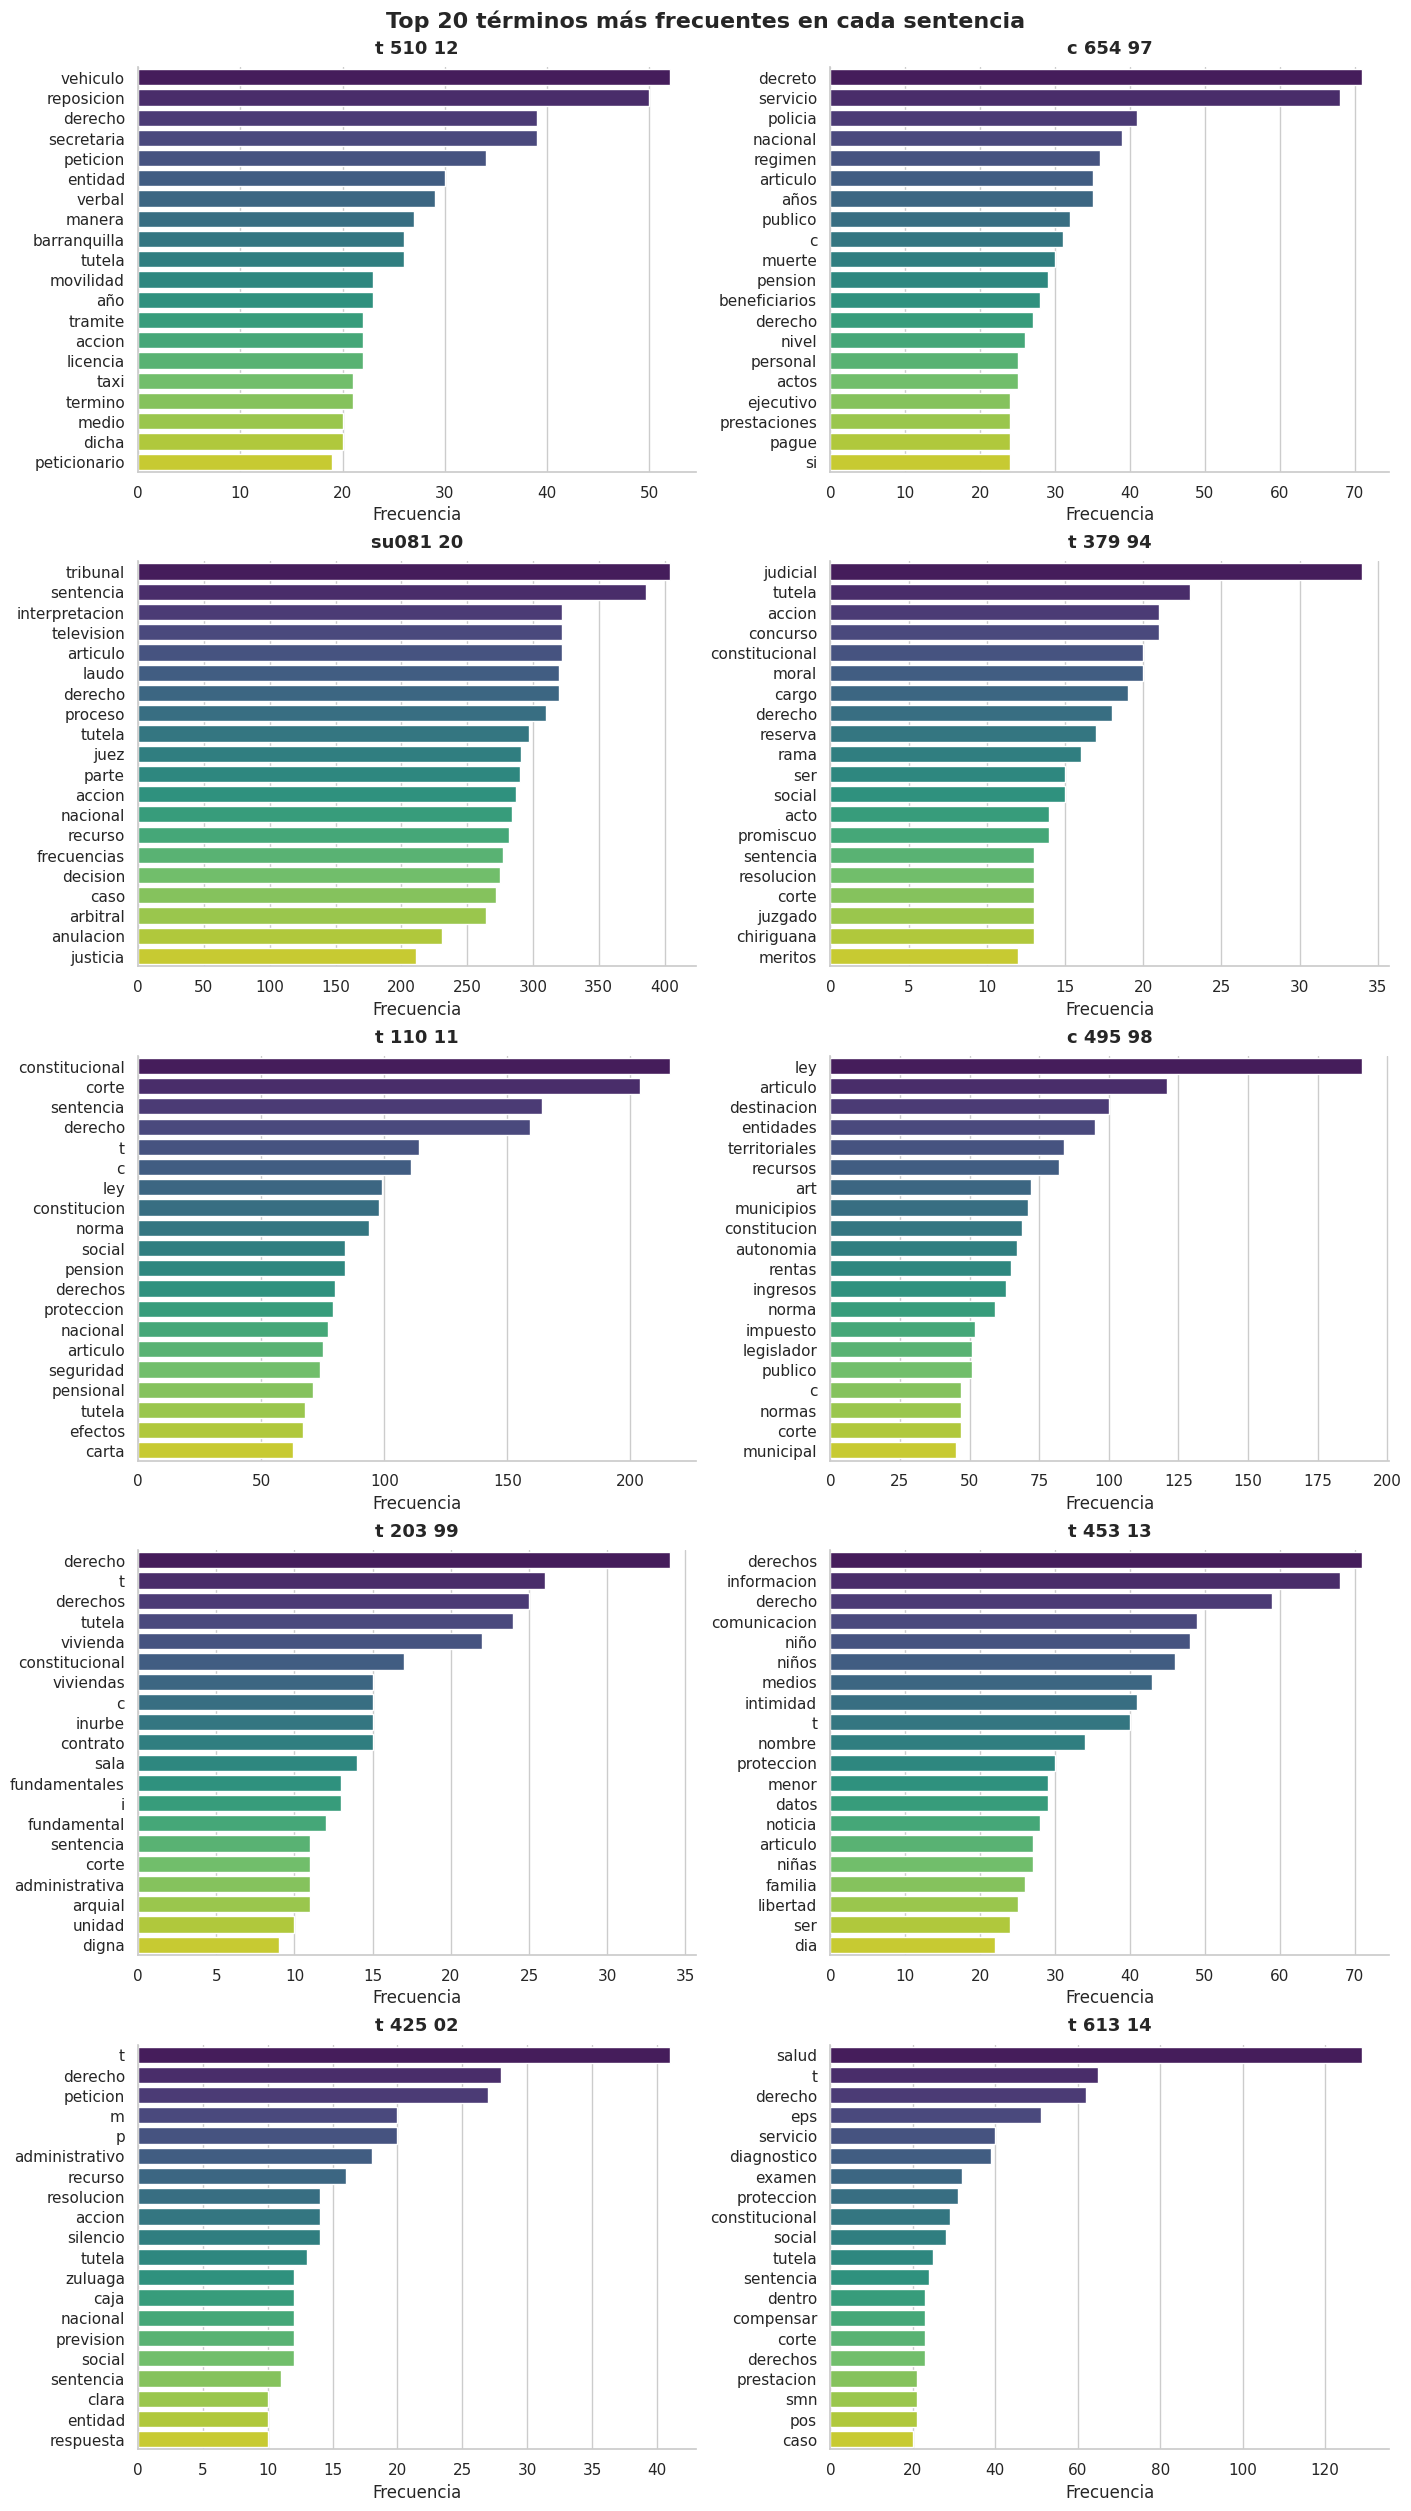

In [ ]:
df_muestra = df.sample(n=10, random_state=42)

frecuencias = frecuencia_terminos(
    df_muestra,
    col_sentencia="SENTENCIA",
    col_lemas="tokens_nltk",
    top_n=20,
    n_cols=2,
)

Grafico que incluye las palabras mas utilizadas incluyendo los stopwords

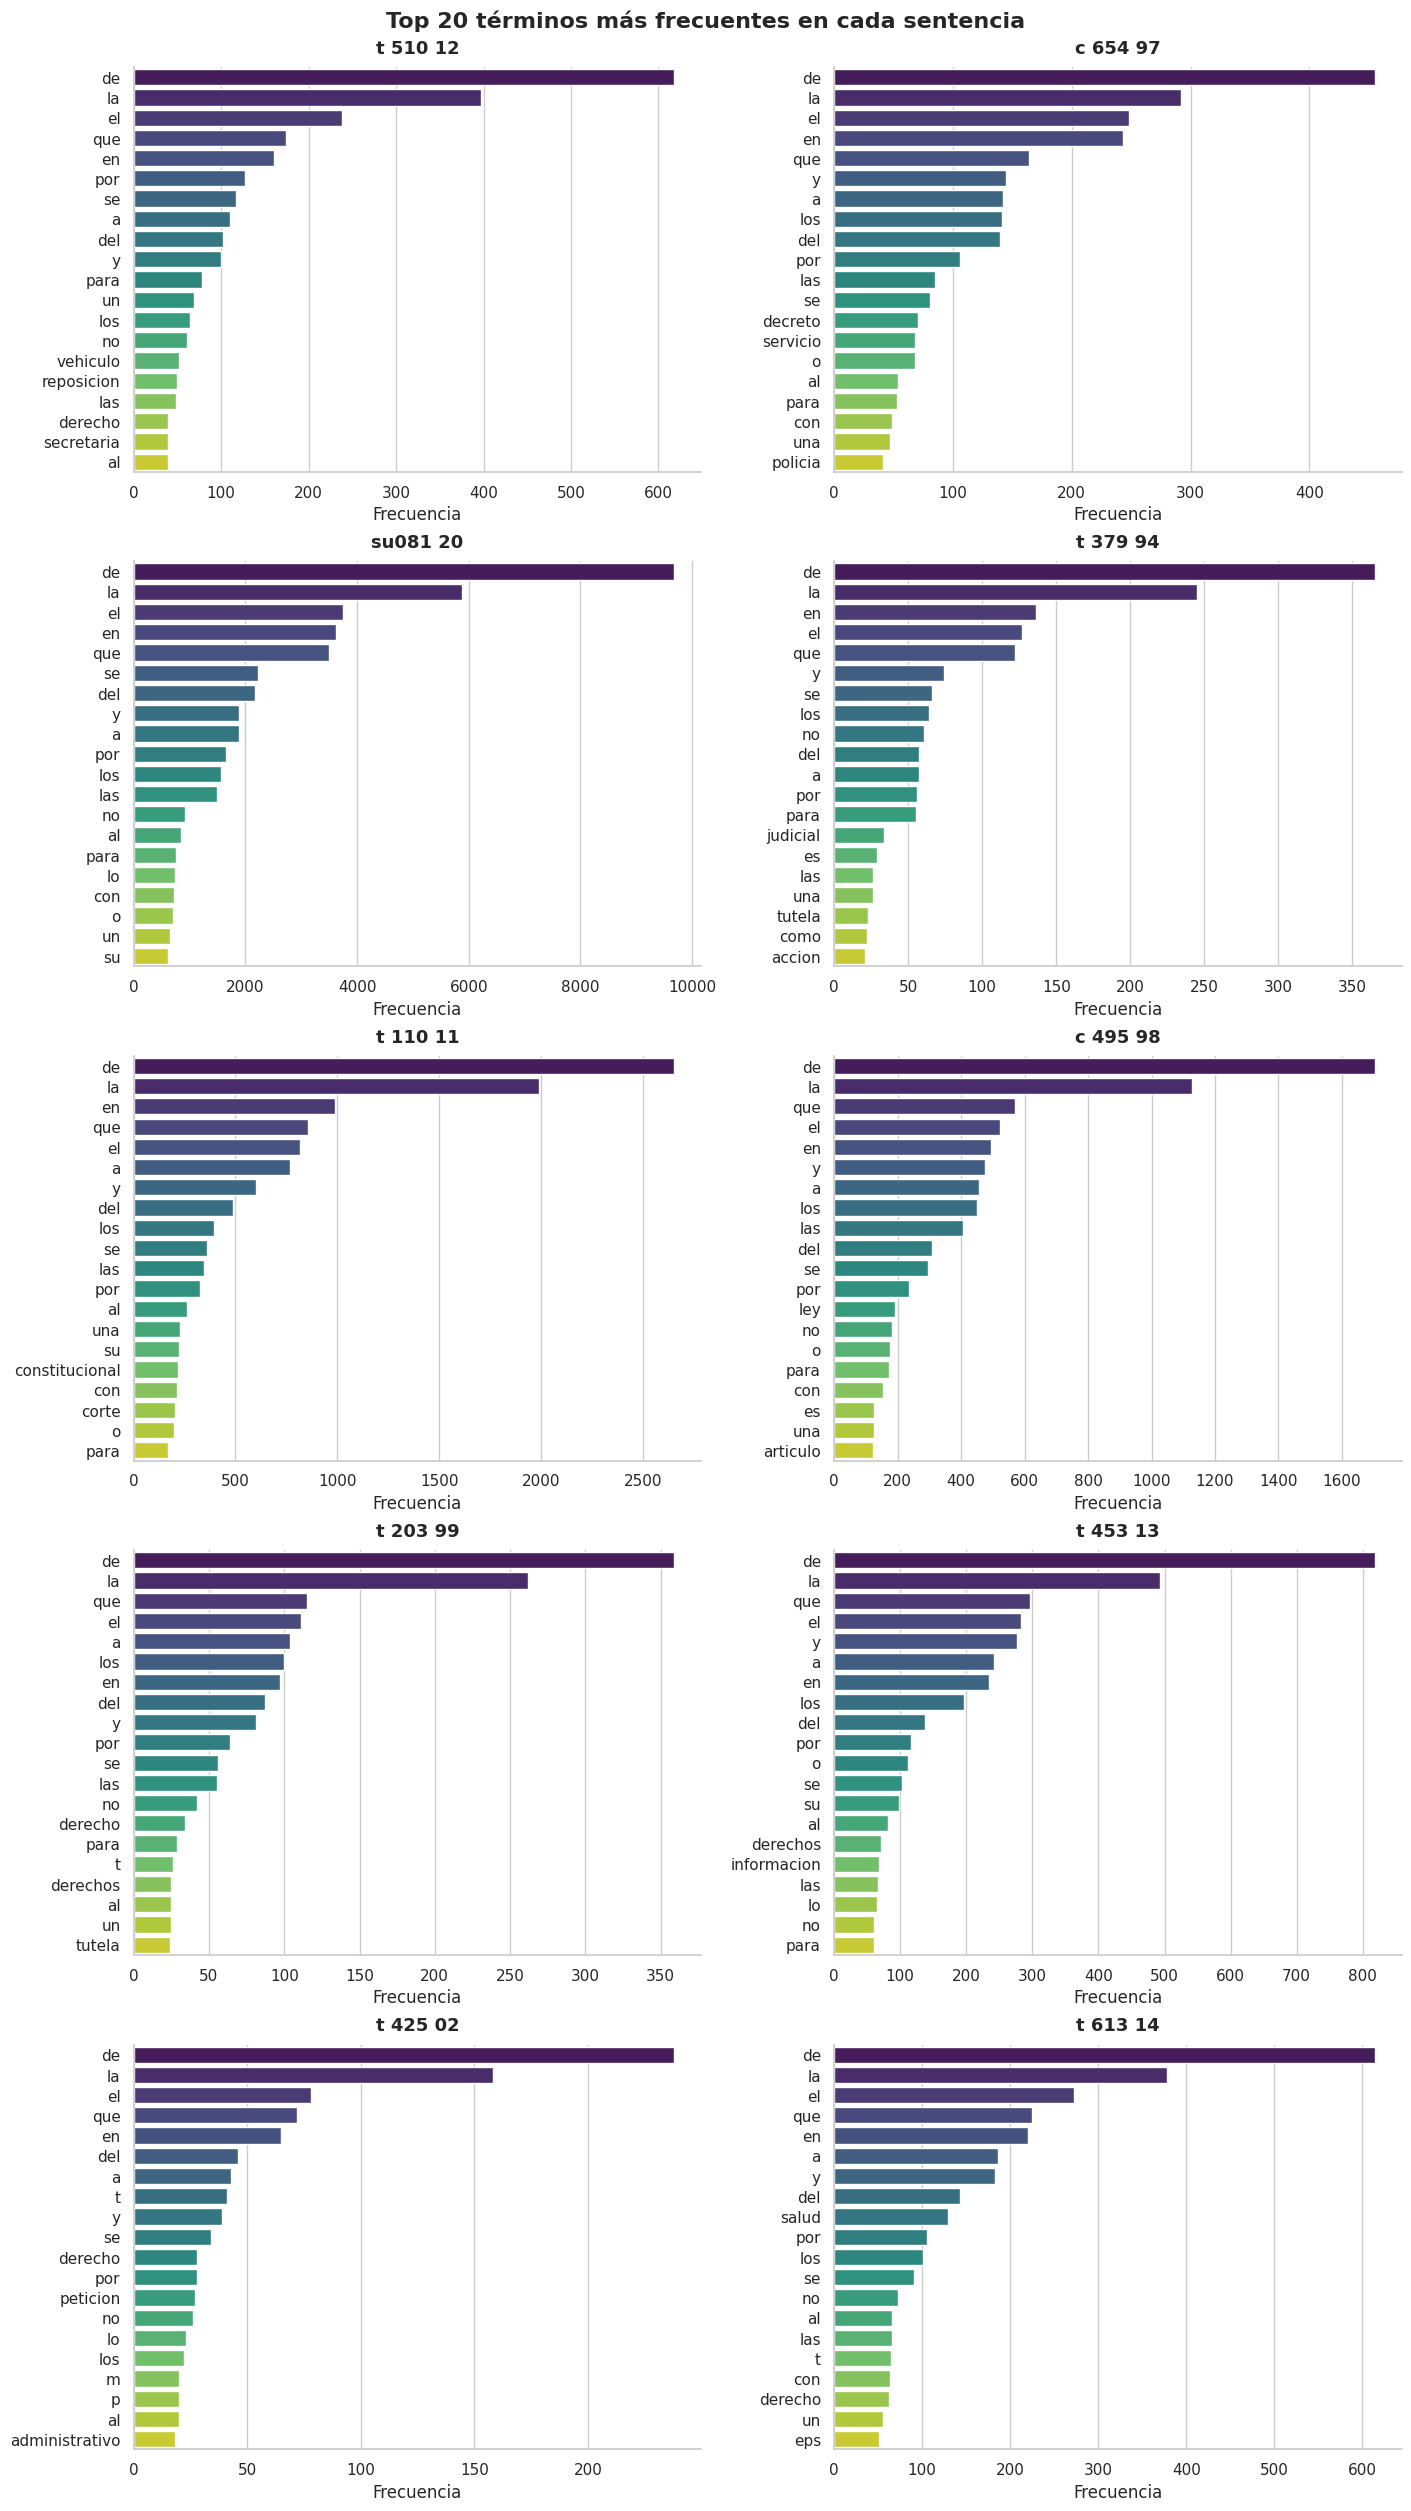

In [ ]:
df_muestra['todo_constop'] = df_muestra['tokens_nltk']+df['stopwords_nltk']
frecuencias = frecuencia_terminos(
    df_muestra,
    col_sentencia="SENTENCIA",
    col_lemas="todo_constop",
    top_n=20,
    n_cols=2,
)

Creacion de la funcion que permite hacer una nube de palabras por las sentencias agrupadas por año de emisión.

In [ ]:

def nube_palabras(df: pd.DataFrame,
                  col_agrupacion: str = 'ANNIO',
                  col_lemas: str = 'tokens_nltk',
                  lista_stopwords: list = None
                  ) -> None:
    """
    Genera nubes de palabras comparativas agrupando los lemas extraídos por spaCy
    según el año en que se emite la sentencia.

    Args:
        df (pd.DataFrame): DataFrame que contiene los datos.
        col_agrupacion (str): Nombre de la columna categórica (año).
        col_lemas (str): Nombre de la columna que contiene las listas de lemas.
    """
    # Agrupar el dataframe por la corriente política
    grupos = df.groupby(col_agrupacion)
    n_grupos = grupos.ngroups

    if n_grupos == 0:
        print("El DataFrame no contiene grupos válidos para graficar.")
        return

    # Calcular dimensiones dinámicas de la cuadrícula (2 columnas fijas)
    cols = 2
    rows = math.ceil(n_grupos / cols)

    # Crear la figura y los ejes
    fig, axes = plt.subplots(rows, cols, figsize=(16, 6 * rows))

    # Asegurar que axes sea iterable (incluso si solo hay 1 o 2 grupos)
    if n_grupos <= 2:
        axes = np.array(axes).flatten() if isinstance(axes, list) else axes.flatten()
    else:
        axes = axes.flatten()

    for i, (annio, df_grupo) in enumerate(grupos):
        # 1. Aplanamiento seguro de la lista de listas, ignorando NaNs
        # Extrae cada 'lema' de cada 'sublista' solo si la sublista es realmente una lista
        lemas_grupo = [
            str(lema)
            for sublista in df_grupo[col_lemas].dropna()
            if isinstance(sublista, list)
            for lema in sublista
        ]

        # Convertir la lista de palabras en un string continuo separado por espacios
        texto_unificado = " ".join(lemas_grupo)

        # Manejo de caso borde: grupo sin palabras válidas
        if not texto_unificado.strip():
            axes[i].axis('off')
            axes[i].set_title(f"{annio}\n(Sin lemas suficientes)", fontsize=14)
            continue

        # Parametrización y generación de la nube de palabras
        wc = WordCloud(
            width=800,
            height=400,
            background_color='white',
            colormap='inferno',     # Paleta de alto contraste
            max_words=80,           # Evita la saturación visual
            stopwords=lista_stopwords,
            collocations=False      # Evita que junte palabras iguales por error de spaCy
        ).generate(texto_unificado)

        # Renderizado en el subplot correspondiente
        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(f'Año: {annio}', fontsize=16, fontweight='bold', pad=15)
        axes[i].axis('off')

    # Ocultar subplots sobrantes si el número de grupos es impar
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    # Ajustar espaciados para que los títulos no se superpongan
    plt.tight_layout()
    plt.show()

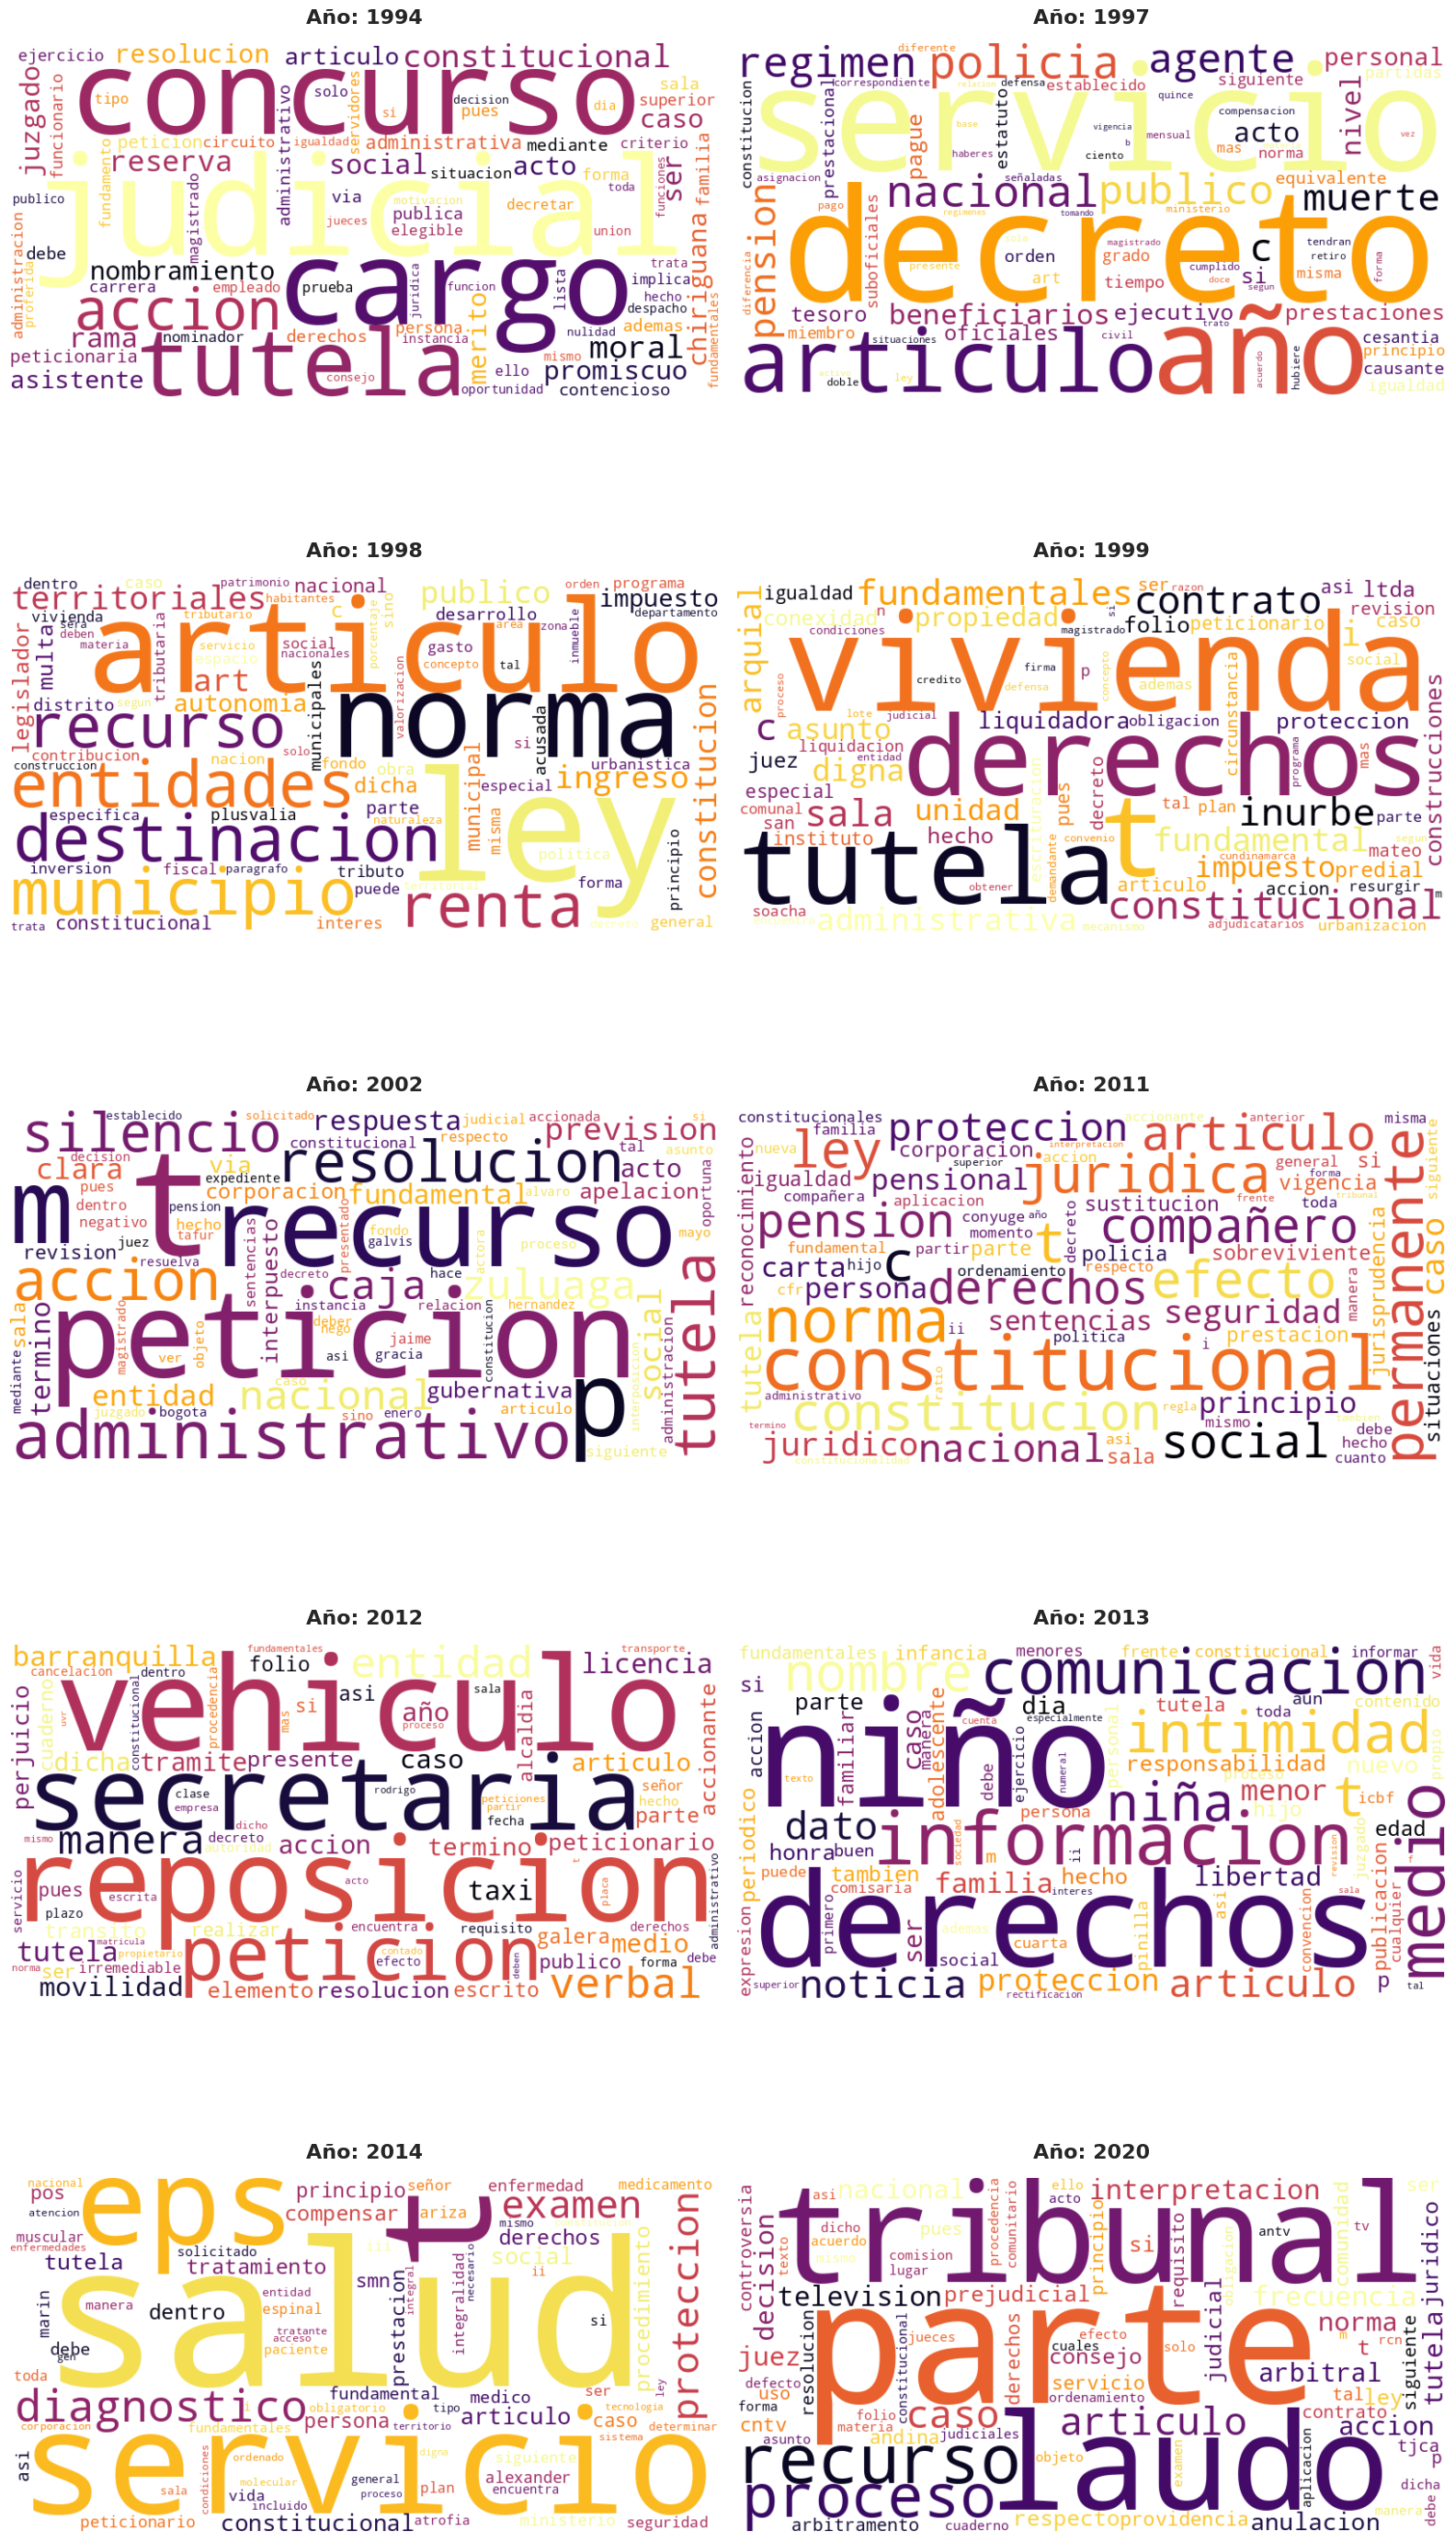

In [ ]:
stopwords_set = ["derecho", "justicia", "corte", "sentencia"]
nube_palabras(df_muestra, lista_stopwords=stopwords_set)